# 7장. 그래프로 데이터의 이야기를 보여주기

이 노트북의 목표는 그래프를 많이 만드는 것이 아닙니다. **분석 질문에 맞는 그래프를 선택하고, 그래프에 들어간 데이터 범위와 수치를 검증하며, 그래프가 보여 주는 사실과 보여 주지 못하는 것을 구분하는 것**이 핵심입니다.

금액성 그래프는 기본적으로 `order_status == "completed"` 범위를 사용합니다. `line_total`은 주문 상세 한 행의 `quantity × unit_price`이며 회계상 순매출로 단정하지 않습니다.

## 0. 사용 방법

- 위에서부터 차례대로 실행합니다.
- 입력은 Chapter 05에서 만든 `data/processed/*_clean.csv`입니다.
- 파일이 없다면 프로젝트 루트에서 `python scripts/preprocess_data.py`를 먼저 실행합니다.
- 그래프를 보기 전에 **시각화용 집계 검증표**를 먼저 확인합니다.
- 대표 그래프마다 `관찰 → 해석 → 한계 → 다음 질문`을 Markdown 셀에 직접 작성합니다.
- 실제 실행 결과 숫자를 보고 작성하며 강의안의 예시를 정답처럼 사용하지 않습니다.

## 1. 시각화 질문과 그래프 선택

| 질문 | 범위·지표 | 그래프 | 선택 이유 |
| --- | --- | --- | --- |
| 카테고리별 completed 주문 금액은 어떻게 다른가? | completed · 금액/수량 | 막대 | 범주별 크기 비교 |
| 월별 completed 주문 금액은 어떻게 변하는가? | completed + 유효 날짜 · 금액/주문 수/객단가 | 선 | 시간 순서와 변화 확인 |
| 전체 상품 가격은 어떻게 분포하는가? | 상품 마스터 · 가격 | 히스토그램 | 값의 집중·꼬리·극단값 후보 확인 |

![질문과 그래프 선택](images/step01_question_chart.png)

그래프보다 질문·범위·지표를 먼저 고정했다.

In [1]:
from pathlib import Path
import sys

CURRENT_DIR = Path.cwd()

def find_project_root(start):
    for candidate in (start, *start.parents):
        if (candidate / 'pyproject.toml').is_file() and (candidate / 'chapter07').is_dir():
            return candidate
    raise FileNotFoundError('프로젝트 루트를 찾을 수 없습니다.')

PROJECT_ROOT = find_project_root(CURRENT_DIR)
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
REPORT_DIR = PROJECT_ROOT / 'reports'
FIGURE_DIR = REPORT_DIR / 'figures'
EVIDENCE_DIR = PROJECT_ROOT / 'chapter07' / 'images'

REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
EVIDENCE_DIR.mkdir(parents=True, exist_ok=True)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print('Python:', sys.executable)
print('현재 실행 위치:', CURRENT_DIR)
print('프로젝트 루트:', PROJECT_ROOT)
print('전처리 데이터 폴더:', PROCESSED_DIR)
print('그래프 저장 폴더:', FIGURE_DIR)
print('제출 이미지 폴더:', EVIDENCE_DIR)

Python: /home/gem/research/프로그램 모음/venvs/llm-data-analysis/bin/python
현재 실행 위치: /home/gem/research/학교 수업/LLM 수업/llm-data-analysis-study
프로젝트 루트: /home/gem/research/학교 수업/LLM 수업/llm-data-analysis-study
전처리 데이터 폴더: /home/gem/research/학교 수업/LLM 수업/llm-data-analysis-study/data/processed
그래프 저장 폴더: /home/gem/research/학교 수업/LLM 수업/llm-data-analysis-study/reports/figures
제출 이미지 폴더: /home/gem/research/학교 수업/LLM 수업/llm-data-analysis-study/chapter07/images


## 2. 검증된 시각화용 데이터를 준비합니다

공통 모듈은 그래프를 그리기 전에 다음을 검사합니다.

- 필수 컬럼
- PK 결측·중복
- `many_to_one` 병합
- 주문/상품 미매칭
- 숫자형 변환 실패
- `completed` 주문 범위
- 카테고리·상품·고객·월별 집계 총합

문제가 있으면 그래프를 만들기 전에 중단합니다.

In [2]:
from src.visualization import (
    prepare_visualization_data,
    setup_korean_font,
)

selected_font = setup_korean_font()
print('사용 한글 폰트:', selected_font or '자동 선택 실패')

viz_data = prepare_visualization_data(PROCESSED_DIR)

products = viz_data['products']
orders = viz_data['orders']
completed_order_sales = viz_data['completed_order_sales']
category_sales = viz_data['category_sales']
monthly_sales = viz_data['monthly_sales']
product_sales = viz_data['product_sales']
customer_sales = viz_data['customer_sales']
order_status = viz_data['order_status']

print('완료 주문 상세 행:', len(completed_order_sales))
print('주문 미매칭 상세:', len(viz_data['unmatched_orders']))
print('상품 미매칭 completed 상세:', len(viz_data['unmatched_products']))
print('날짜 결측 completed 상세:', len(viz_data['invalid_date_sales']))

사용 한글 폰트: Noto Sans CJK KR
완료 주문 상세 행: 446
주문 미매칭 상세: 2
상품 미매칭 completed 상세: 16
날짜 결측 completed 상세: 6


In [3]:
viz_data["visualization_validation"]

,check,expected,actual,difference,passed
0,category_completed_amount,141340000.0,141340000.0,0.0,True
1,product_completed_amount,141340000.0,141340000.0,0.0,True
2,customer_completed_amount,141340000.0,141340000.0,0.0,True
3,monthly_completed_amount_valid_dates,139437000.0,139437000.0,0.0,True


### 검증 결과

![그래프 전 검증](images/step02_validation.png)

- completed 상세 446행, 179개 주문, source 합계 141,340,000
- 카테고리·상품·고객 집계는 source 합계와 일치
- 월별 집계 139,437,000은 유효 날짜 범위 합계와 일치
- 날짜 결측 6행(1,903,000)은 월별 그래프에서만 제외
- 주문 미매칭 2행과 상품 미매칭 completed 16행은 삭제하지 않고 기록·보존

모든 검증표가 `passed=True`이고 범위별 제외 금액이 설명되므로 시각화를 진행했다.

## 3. 카테고리별 완료 주문 금액 — 막대그래프

범주별 크기 비교이므로 막대그래프를 사용합니다. 값 축은 0에서 시작합니다. 금액이 크다는 사실만으로 선호도가 높다고 단정하지 않습니다.

In [4]:
from src.visualization import plot_category_sales

category_sales[["category", "total_quantity", "completed_amount", "amount_ratio_pct"]]

,category,total_quantity,completed_amount,amount_ratio_pct
10,패션,290.0,32940000.0,23.31
7,식품,226.0,25035000.0,17.71
9,전자기기,176.0,21485000.0,15.20
1,도서,174.0,17663000.0,12.50
3,뷰티,168.0,17103000.0,12.10
6,스포츠,165.0,13237000.0,9.37
5,생활용품,108.0,7001000.0,4.95
0,Unknown,34.0,4015000.0,2.84
4,생활 용품,17.0,2108000.0,1.49
2,뷰 티,12.0,648000.0,0.46


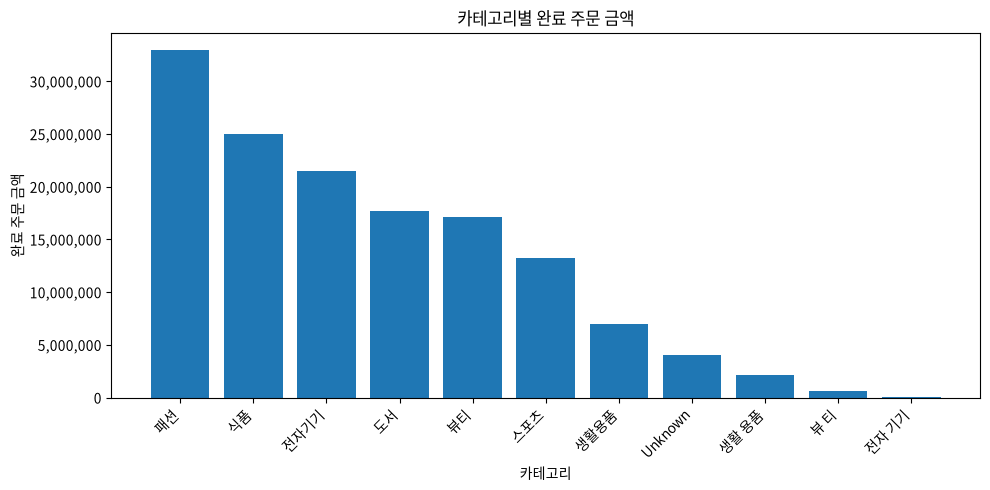

PosixPath('/home/gem/research/학교 수업/LLM 수업/llm-data-analysis-study/chapter07/images/graph01.png')

In [5]:
category_path = plot_category_sales(
    category_sales,
    EVIDENCE_DIR / 'graph01.png',
    show=True,
)
category_path

### 대표 그래프 1 — 카테고리별 completed 주문 금액

![대표 그래프 1](images/graph01.png)

- **원본 집계값:** 패션 32,940,000(23.31%)·수량 290, 식품 25,035,000, 전자기기 21,485,000
- **관찰:** 패션이 금액과 수량 모두 가장 크다.
- **해석:** 패션이 completed 주문 금액에서 가장 큰 비중을 차지한다.
- **업무 의미:** 우선 상세 분석할 카테고리 후보를 정할 수 있다.
- **한계·다음 질문:** 금액만으로 선호·수익성을 판단할 수 없다. `전자기기/전자 기기`처럼 분리된 표기는 Chapter 05 기준으로 재검토하고, 상품별 수량·단가·집중도를 확인한다.

## 4. 월별 완료 주문 금액 — 선그래프

시간 순서가 핵심인 질문이므로 선그래프를 사용합니다. 첫 달과 마지막 달이 완전한 한 달인지, 중간 월이 비어 있다면 실제 0인지 데이터 누락인지 확인합니다.

In [6]:
from src.visualization import plot_monthly_sales

monthly_sales[
    [
        "order_month",
        "completed_amount",
        "completed_order_count",
        "average_completed_order_amount",
    ]
]

,order_month,completed_amount,completed_order_count,average_completed_order_amount
0,2025-07,9561000.0,11,869182.0
1,2025-08,9362000.0,17,550706.0
2,2025-09,5299000.0,4,1324750.0
3,2025-10,12629000.0,17,742882.0
4,2025-11,9583000.0,16,598938.0
5,2025-12,8581000.0,12,715083.0
6,2026-01,8135000.0,9,903889.0
7,2026-02,7689000.0,12,640750.0
8,2026-03,7247000.0,13,557462.0
9,2026-04,11459000.0,14,818500.0


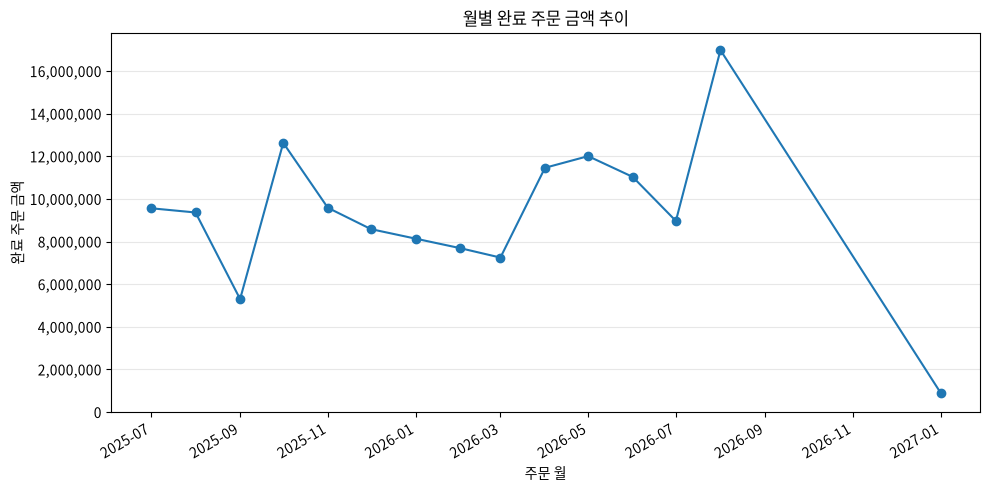

PosixPath('/home/gem/research/학교 수업/LLM 수업/llm-data-analysis-study/chapter07/images/graph02.png')

In [7]:
monthly_path = plot_monthly_sales(
    monthly_sales,
    EVIDENCE_DIR / 'graph02.png',
    show=True,
)
monthly_path

### 대표 그래프 2 — 월별 completed 주문 금액

![대표 그래프 2](images/graph02.png)

- **원본 집계값:** 2026-08은 16,980,000·15건·평균 1,132,000으로 금액 최고다.
- **관찰:** 월별 등락이 있고 2026-08 이후 2027-01 한 건만 있어 기간이 연속적이지 않다.
- **해석:** 2026-08의 높은 금액에는 주문 수뿐 아니라 높은 평균 주문 금액도 함께 작용했을 수 있다.
- **업무 의미:** 금액 변화가 큰 월을 상세 점검할 수 있다.
- **한계·다음 질문:** 누락 월을 0으로 해석하거나 프로모션 효과로 단정할 수 없다. 주문별 금액과 카테고리 구성을 확인한다.

## 5. 상품 가격 분포 — 히스토그램

상품 가격은 상품 마스터의 속성이므로 주문 상태와 무관하게 전체 상품을 봅니다. `bins` 값에 따라 모양이 달라질 수 있으므로 구간 수 하나만 보고 이상값을 확정하지 않습니다.

In [8]:
from src.visualization import plot_product_price_hist

products["price"].describe()

count    9.600000e+01
mean     2.048958e+05
std      1.011848e+06
min      5.000000e+03
25%      5.275000e+04
50%      9.450000e+04
75%      1.532500e+05
max      9.999999e+06
Name: price, dtype: float64

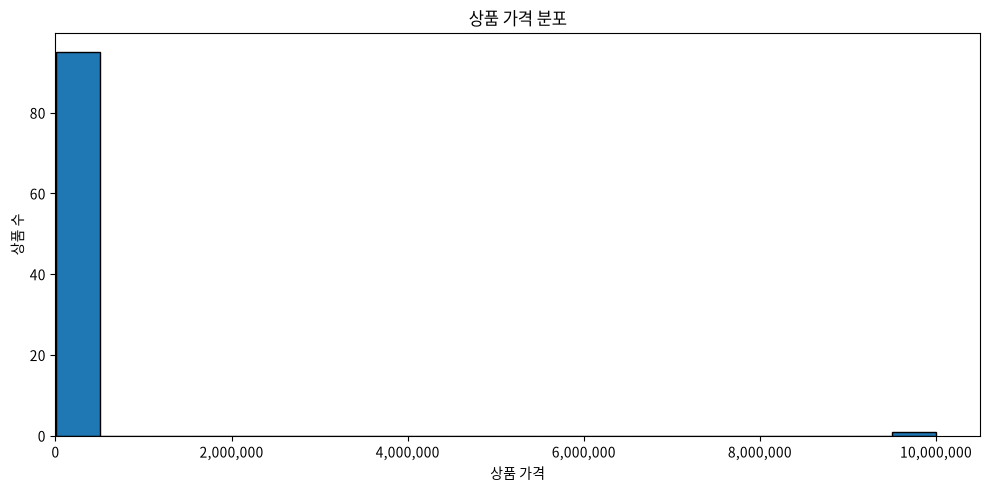

PosixPath('/home/gem/research/학교 수업/LLM 수업/llm-data-analysis-study/chapter07/images/graph03.png')

In [9]:
price_hist_path = plot_product_price_hist(
    products,
    EVIDENCE_DIR / 'graph03.png',
    show=True,
    bins=20,
)
price_hist_path

### 대표 그래프 3 — 상품 가격 분포

![대표 그래프 3](images/graph03.png)

- **원본 집계값:** 96개 상품, 중앙값 94,500, 75% 값 153,250, 최댓값 9,999,999
- **관찰:** 대부분 200,000 이하인데 하나의 극단값 때문에 오른쪽 꼬리가 매우 길다.
- **해석:** 평균 204,896은 극단값 영향을 크게 받아 대표값으로 주의해야 한다.
- **업무 의미:** 가격 요약에는 중앙값·분위수와 원본 확인이 필요하다.
- **한계·다음 질문:** 극단값을 오류로 자동 삭제할 수 없다. 상품 원장과 업무 의미를 확인한다.

`bins=10·20·30`에서도 “대부분 저가 구간 + 하나의 먼 값”이라는 큰 패턴은 유지되지만 세부 구간 인상은 달라진다.

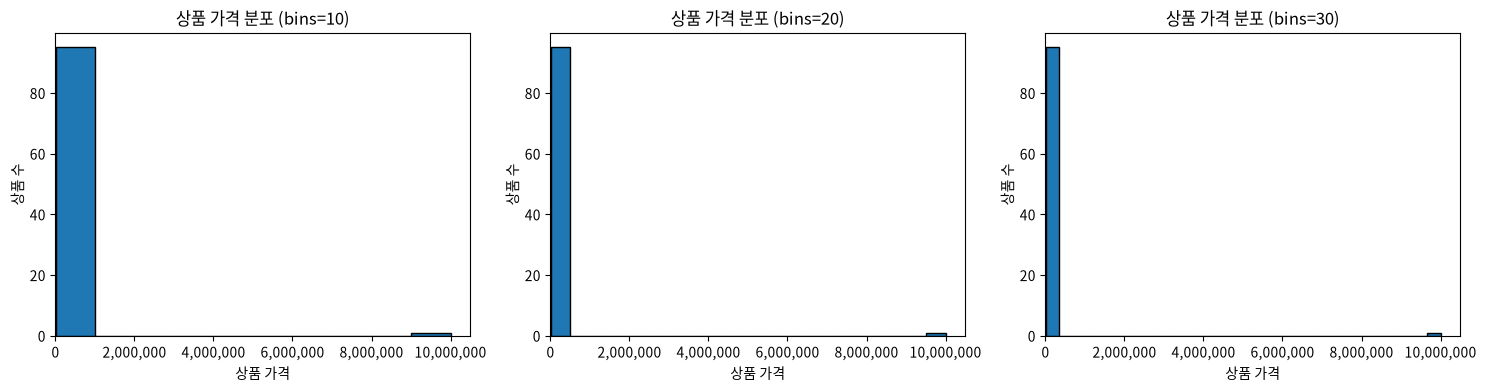

PosixPath('/home/gem/research/학교 수업/LLM 수업/llm-data-analysis-study/reports/figures/ch07_product_price_bins_comparison.png')

In [10]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, bins in zip(axes, [10, 20, 30]):
    ax.hist(products['price'].dropna(), bins=bins, edgecolor='black')
    ax.set_title(f'상품 가격 분포 (bins={bins})')
    ax.set_xlabel('상품 가격')
    ax.set_ylabel('상품 수')
    ax.set_xlim(left=0)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value:,.0f}'))
fig.tight_layout()
bins_path = FIGURE_DIR / 'ch07_product_price_bins_comparison.png'
fig.savefig(bins_path, dpi=150, bbox_inches='tight')
plt.show()
bins_path

## 6. 상품 가격과 완료 주문 판매 수량 — 산점도

한 점은 상품 하나입니다. 관계가 보여도 **가격이 판매 수량의 원인**이라고 단정하지 않습니다.

In [11]:
from src.visualization import plot_price_quantity_scatter

product_sales[["price", "completed_quantity", "completed_amount"]].head(10)

,price,completed_quantity,completed_amount
73,183000.0,37.0,6771000.0
94,96000.0,70.0,6720000.0
95,187000.0,26.0,4862000.0
63,193000.0,22.0,4246000.0
52,152000.0,26.0,3952000.0
68,168000.0,21.0,3528000.0
47,171000.0,19.0,3249000.0
37,172000.0,17.0,2924000.0
49,183000.0,15.0,2745000.0
84,145000.0,18.0,2610000.0


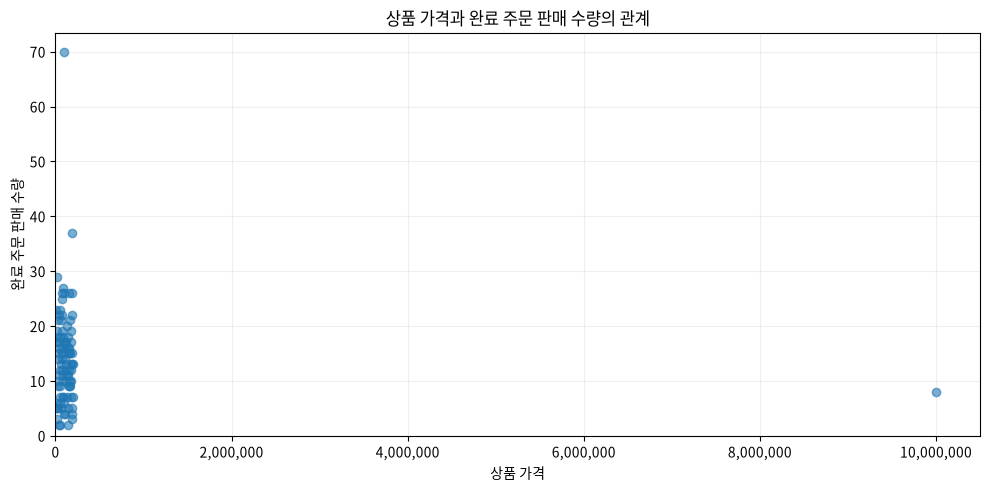

PosixPath('/home/gem/research/학교 수업/LLM 수업/llm-data-analysis-study/reports/figures/ch07_price_completed_quantity_scatter.png')

In [12]:
scatter_path = plot_price_quantity_scatter(
    product_sales,
    FIGURE_DIR / 'ch07_price_completed_quantity_scatter.png',
    show=True,
)
scatter_path

### 산점도 추가 관찰

가격과 completed 판매 수량의 상관계수는 약 -0.07로 뚜렷한 선형 관계가 보이지 않는다. 극단 가격과 미매칭 상품이 있으므로 이 그래프만으로 가격이 판매량의 원인이라고 판단하지 않는다.

## 7. 완료 주문 구매 금액 상위 고객 — 익명 가로 막대그래프

공개 그래프에서는 고객 이름이나 원본 고객 ID를 직접 표시하지 않고 **순위 기반 익명 라벨**을 사용합니다. Top 10은 전체 고객 분포가 아니라 일부 고객만 보여 줍니다.

In [13]:
from src.visualization import plot_top_customers

top_customer_table = customer_sales.head(10)[
    ["completed_order_count", "completed_amount", "average_completed_order_amount"]
].copy()
top_customer_table.insert(0, "customer_label", [f"Customer {rank:02d}" for rank in range(1, 11)])
top_customer_table

,customer_label,completed_order_count,completed_amount,average_completed_order_amount
1,Customer 01,3,6702000.0,2234000.0
7,Customer 02,4,5204000.0,1301000.0
57,Customer 03,3,4311000.0,1437000.0
59,Customer 04,4,4001000.0,1000250.0
47,Customer 05,6,3977000.0,662833.0
66,Customer 06,2,3966000.0,1983000.0
11,Customer 07,4,3808000.0,952000.0
27,Customer 08,4,3656000.0,914000.0
19,Customer 09,4,3201000.0,800250.0
13,Customer 10,3,3109000.0,1036333.0


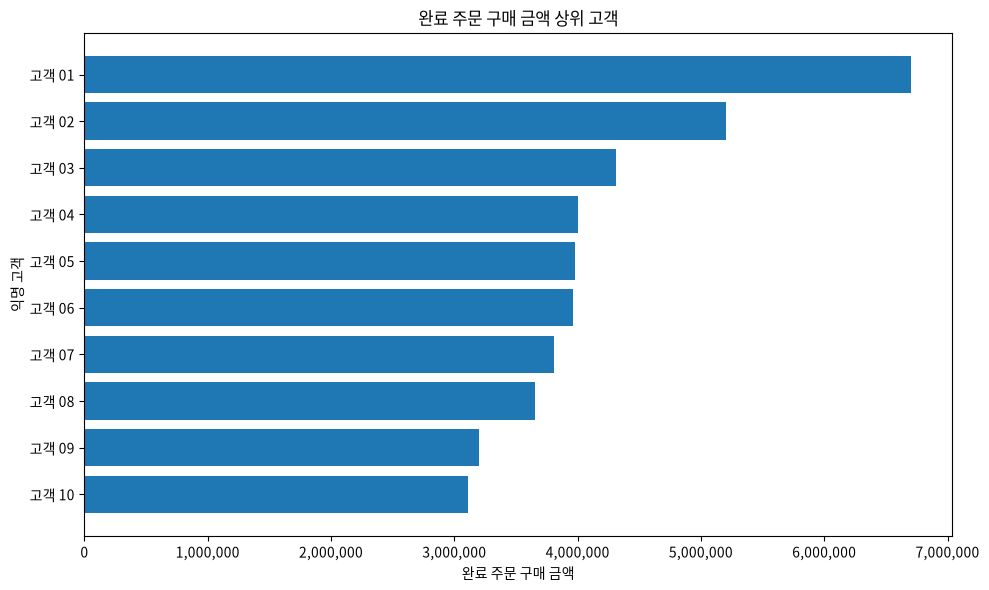

PosixPath('/home/gem/research/학교 수업/LLM 수업/llm-data-analysis-study/reports/figures/ch07_top_customers_anonymized_barh.png')

In [14]:
top_customer_path = plot_top_customers(
    customer_sales,
    FIGURE_DIR / 'ch07_top_customers_anonymized_barh.png',
    show=True,
    top_n=10,
)
top_customer_path

### 상위 고객 그래프 해석 주의

순위 기반 익명 라벨만 표시해 개인정보를 노출하지 않았다. Top 10은 전체 분포가 아니며, 금액이 높다는 사실만으로 충성 고객이라고 부르지 않는다. 주문 횟수·평균 주문 금액·분석 기간을 함께 확인해야 한다.

## 8. 전체 주문 상태 — 막대그래프

이 그래프만 전체 주문을 사용합니다. 상태별 규모는 보여 주지만 취소·환불의 원인을 설명하지 않습니다.

In [15]:
from src.visualization import plot_order_status

order_status

,order_status,order_count
0,completed,180
1,cancelled,63
2,refunded,57


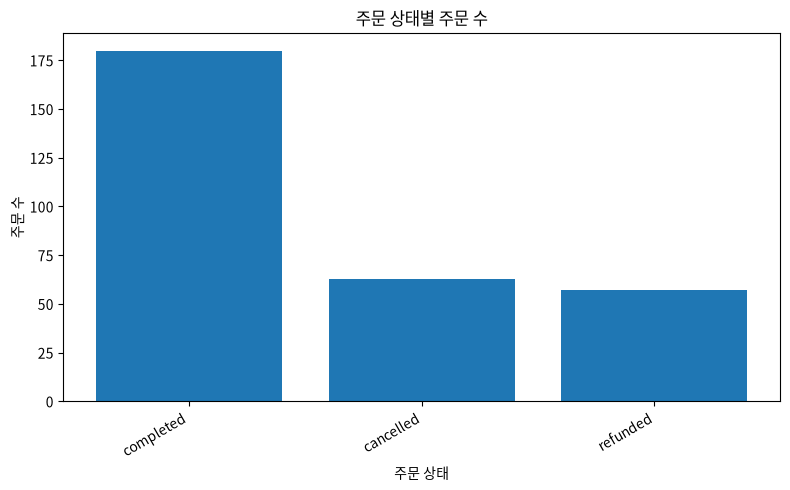

PosixPath('/home/gem/research/학교 수업/LLM 수업/llm-data-analysis-study/reports/figures/ch07_order_status_bar.png')

In [16]:
order_status_path = plot_order_status(
    order_status,
    FIGURE_DIR / 'ch07_order_status_bar.png',
    show=True,
)
order_status_path

## 9. 그래프 정확성과 오해 가능성 점검

![최종 정확성 점검](images/step03_final_check.png)

- [x] 그래프 값과 집계표 값 일치
- [x] 제목·축 이름·단위 확인
- [x] 막대 값 축 0부터 시작
- [x] 월별 x축 시간순 정렬
- [x] 데이터 없는 월을 0으로 채우지 않음
- [x] 고객 그래프 익명 처리
- [x] completed와 전체 주문 범위 구분

**발견한 위험:** 가격 극단값이 히스토그램의 대부분을 한 구간에 압축하고, 월별 선은 긴 데이터 공백을 연속 변화처럼 보이게 할 수 있다. 극단값은 원본 확인 대상으로 기록하고, 월별 해석에는 누락 기간을 명시했다.

In [17]:
source_total = float(completed_order_sales['line_total'].sum())
invalid_date_total = float(viz_data['invalid_date_sales']['line_total'].sum())

chart_checks = {
    'category_total_matches_source': float(category_sales['completed_amount'].sum()) == source_total,
    'monthly_total_matches_valid_dates': (
        float(monthly_sales['completed_amount'].sum())
        == source_total - invalid_date_total
    ),
    'category_sorted_desc': category_sales['completed_amount'].is_monotonic_decreasing,
    'month_sorted_asc': monthly_sales['month_start'].is_monotonic_increasing,
    'bar_axis_starts_at_zero': True,
    'missing_months_not_filled_with_zero': True,
    'customer_labels_anonymized': True,
}
assert all(chart_checks.values())
chart_checks

{'category_total_matches_source': True,
 'monthly_total_matches_valid_dates': True,
 'category_sorted_desc': True,
 'month_sorted_asc': True,
 'bar_axis_starts_at_zero': True,
 'missing_months_not_filled_with_zero': True,
 'customer_labels_anonymized': True}

## 10. 공통 함수로 전체 그래프와 보고서를 다시 생성합니다

Notebook에서 개별 그래프를 이해한 뒤 공통 함수를 사용해 같은 결과를 재현합니다.

In [18]:
from src.visualization import (
    build_visualization_report,
    create_all_figures,
    create_visualization_summary,
)

saved_figures = create_all_figures(viz_data, FIGURE_DIR, show=False)
summary = create_visualization_summary()

summary_path = REPORT_DIR / 'ch07_visualization_summary.md'
summary_path.write_text(
    build_visualization_report(summary),
    encoding='utf-8',
)

print('생성 파일')
for path in saved_figures:
    print('-', path)

print('요약 보고서:', summary_path)
summary

생성 파일
- /home/gem/research/학교 수업/LLM 수업/llm-data-analysis-study/reports/figures/ch07_category_completed_amount_bar.png
- /home/gem/research/학교 수업/LLM 수업/llm-data-analysis-study/reports/figures/ch07_monthly_completed_amount_line.png
- /home/gem/research/학교 수업/LLM 수업/llm-data-analysis-study/reports/figures/ch07_product_price_hist.png
- /home/gem/research/학교 수업/LLM 수업/llm-data-analysis-study/reports/figures/ch07_price_completed_quantity_scatter.png
- /home/gem/research/학교 수업/LLM 수업/llm-data-analysis-study/reports/figures/ch07_top_customers_anonymized_barh.png
- /home/gem/research/학교 수업/LLM 수업/llm-data-analysis-study/reports/figures/ch07_order_status_bar.png
요약 보고서: /home/gem/research/학교 수업/LLM 수업/llm-data-analysis-study/reports/ch07_visualization_summary.md


,chart,question,scope,interpretation_point,file_name
0,카테고리별 완료 주문 금액,카테고리별 완료 주문 금액은 어떻게 다른가?,completed orders,금액 차이는 수량·단가 등 추가 지표로 확인,ch07_category_completed_amount_bar.png
1,월별 완료 주문 금액,월별 완료 주문 금액은 어떻게 변하는가?,completed orders + valid order_date,증감은 관찰이며 원인은 추가 데이터 필요,ch07_monthly_completed_amount_line.png
2,상품 가격 분포,상품 가격은 어떤 구간에 몰려 있는가?,product master,상품 구성 분포이며 판매 선호를 의미하지 않음,ch07_product_price_hist.png
3,상품 가격과 완료 주문 판매 수량,상품 가격과 완료 주문 판매 수량은 어떤 패턴을 보이는가?,completed orders aggregated by product,관계는 인과를 의미하지 않음,ch07_price_completed_quantity_scatter.png
4,완료 주문 구매 금액 상위 고객,완료 주문 구매 금액 상위 고객군은 어떻게 구성되는가?,completed orders aggregated by customer,Top N이며 충성도를 자동 의미하지 않음,ch07_top_customers_anonymized_barh.png
5,주문 상태별 주문 수,주문 상태별 주문 수는 어떻게 다른가?,all orders,상태 분포만으로 취소·환불 원인을 알 수 없음,ch07_order_status_bar.png


In [19]:
import subprocess

script_result = subprocess.run(
    [sys.executable, str(PROJECT_ROOT / 'scripts' / 'run_visualization.py')],
    cwd=PROJECT_ROOT,
    capture_output=True,
    text=True,
    check=True,
)
print(script_result.stdout)

expected = [
    REPORT_DIR / 'figures' / name for name in [
        'ch07_category_completed_amount_bar.png',
        'ch07_monthly_completed_amount_line.png',
        'ch07_product_price_hist.png',
        'ch07_price_completed_quantity_scatter.png',
        'ch07_top_customers_anonymized_barh.png',
        'ch07_order_status_bar.png',
    ]
]
expected.append(REPORT_DIR / 'ch07_visualization_summary.md')
assert all(path.exists() and path.stat().st_size > 0 for path in expected)
print('재현 산출물 확인: PASS')

사용 한글 폰트: Noto Sans CJK KR

[시각화용 집계 검증]
                               check    expected      actual  difference  passed
           category_completed_amount 141340000.0 141340000.0         0.0    True
            product_completed_amount 141340000.0 141340000.0         0.0    True
           customer_completed_amount 141340000.0 141340000.0         0.0    True
monthly_completed_amount_valid_dates 139437000.0 139437000.0         0.0    True
주문 정보 미매칭 주문 상세: 2
상품 정보 미매칭 완료 주문 상세: 16
월별 집계에서 제외되는 날짜 결측 완료 주문 상세: 6

7장 시각화 완료

[생성한 그래프 파일]
- /home/gem/research/학교 수업/LLM 수업/llm-data-analysis-study/reports/figures/ch07_category_completed_amount_bar.png (40665 bytes)
- /home/gem/research/학교 수업/LLM 수업/llm-data-analysis-study/reports/figures/ch07_monthly_completed_amount_line.png (82827 bytes)
- /home/gem/research/학교 수업/LLM 수업/llm-data-analysis-study/reports/figures/ch07_product_price_hist.png (22767 bytes)
- /home/gem/research/학교 수업/LLM 수업/llm-data-analysis-study/reports/figures/ch07_price_c

### LLM 시각화 검토

- **Safe Context:** 익명 집계표, 질문, completed 범위, 축·단위 정보만 제공
- **Prompt:** 월별 completed 금액 선그래프의 적합성, 제목·축, 오해 위험, 추가 지표를 검토하되 원인을 만들지 말 것
- **제안 요약:** 시간순 정렬, y축 0 시작, 주문 수·평균 주문 금액 병행, 누락 월 표시
- **판단:** 정렬·축·추가 지표는 사용했다. 누락 월을 0으로 채우는 방식은 “거래 없음”으로 오해될 수 있어 보류하고 공백을 명시했다.
- **직접 확인:** 원본 집계값, 날짜 실패 6행, 제외 금액 1,903,000을 코드로 검증했다.

## 11. Chapter 07 최종 판단

- **가장 중요한 그래프:** 월별 completed 주문 금액 선그래프. 금액 변화와 동시에 기간 공백·날짜 제외 범위를 확인하게 하기 때문이다.
- **보여 준 사실:** 유효 날짜 기준 2026-08 금액이 16,980,000으로 가장 높다.
- **말할 수 없는 것:** 프로모션·계절성·선호·수익성 같은 원인은 현재 데이터로 확인할 수 없다.
- **가장 주의한 점:** 질문별 범위를 섞지 않고, 그래프 전에 집계 총합·정렬·미매칭을 검증하는 것이다.
- **다음 질문:** 2026-08 금액 증가는 주문 수, 주문당 금액, 특정 카테고리 중 무엇의 영향이 큰가?

### 제출 정보

- GitHub ID: `chocoemong1`
- 작성일: 2026-10-14
- 최종 URL: [chapter07.ipynb](https://github.com/chocoemong1/llm-data-analysis-study/blob/main/chapter07/chapter07.ipynb)

### 완료 체크

- [x] 질문 3개와 그래프 선택 이유 작성
- [x] completed 범위와 집계 검증
- [x] 대표 그래프 3개 및 원본 수치 교차 확인
- [x] 축·단위·정렬·기간 공백 점검
- [x] 관찰·해석·업무 의미·한계 구분
- [x] 고객 개인정보 익명 처리
- [x] LLM 제안 직접 검증
- [x] 스크립트 재실행 및 산출물 확인
- [x] 개인정보·Secret 제외